In [1]:
import re, random, json, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

SEED = 42
rng = np.random.default_rng(SEED)
random.seed(SEED)
OUT = Path("ivi_outputs"); (OUT / "figures").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

In [2]:
LAYERS = [  # id, log tag, description, mean latency (ms), pid
    ("L1", "InputDispatcher",     "Touch / steering-wheel key event",        3.0,  812),
    ("L2", "CarApp",              "Media / Navigation app + MediaController", 7.0, 1544),
    ("L3", "MediaSessionService", "MediaSession callback dispatch",           4.5, 1021),
    ("L4", "CarAudioService",     "Audio focus + volume-group routing",       6.5, 1021),
    ("L5", "AudioFlinger",        "AudioTrack + mixer thread",                9.0,  690),
    ("L6", "AudioHAL",            "IStreamOut / IAudioControl",              14.0,  702),
    ("L7", "DSP_Amp",             "Codec, DSP and amplifier",                 3.5,  655),
]
LAYER_IDS = [l[0] for l in LAYERS]
TAG = {l[0]: l[1] for l in LAYERS}; TAG2LAYER = {l[1]: l[0] for l in LAYERS}
MEAN = {l[0]: l[3] for l in LAYERS}; PID = {l[0]: l[4] for l in LAYERS}

ACTIONS = {
 "PLAY": dict(weight=.20, hal=1.8, msgs={
    "L1": "KEYCODE_MEDIA_PLAY received (source=touch)",
    "L2": "onPlayClicked -> transportControls.play()",
    "L3": "dispatchPlay to session com.ivi.music",
    "L4": "requestAudioFocus(USAGE_MEDIA, GAIN)",
    "L5": "createTrack(stream=MUSIC, 44100 Hz) + start()",
    "L6": "IStreamOut.open + write() first buffer",
    "L7": "codec unmute, amplifier enable"}),
 "PAUSE": dict(weight=.14, hal=1.0, msgs={
    "L1": "KEYCODE_MEDIA_PAUSE received (source=steering_wheel)",
    "L2": "onPauseClicked -> transportControls.pause()",
    "L3": "dispatchPause to session com.ivi.music",
    "L4": "abandonAudioFocus(USAGE_MEDIA) delayed",
    "L5": "AudioTrack.pause() + drain",
    "L6": "IStreamOut.pause()",
    "L7": "amplifier mute ramp"}),
 "NEXT": dict(weight=.20, hal=1.3, msgs={
    "L1": "KEYCODE_MEDIA_NEXT received (source=steering_wheel)",
    "L2": "onNextClicked -> transportControls.skipToNext()",
    "L3": "dispatchSkipToNext to session com.ivi.music",
    "L4": "focus retained, no change",
    "L5": "AudioTrack.flush() + new track",
    "L6": "IStreamOut.flush() + write()",
    "L7": "DSP buffer reset"}),
 "PREV": dict(weight=.06, hal=1.3, msgs={
    "L1": "KEYCODE_MEDIA_PREVIOUS received (source=touch)",
    "L2": "onPrevClicked -> transportControls.skipToPrevious()",
    "L3": "dispatchSkipToPrevious to session com.ivi.music",
    "L4": "focus retained, no change",
    "L5": "AudioTrack.flush() + new track",
    "L6": "IStreamOut.flush() + write()",
    "L7": "DSP buffer reset"}),
 "VOL_UP": dict(weight=.14, hal=.8, msgs={
    "L1": "KEYCODE_VOLUME_UP received (source=steering_wheel)",
    "L2": "SystemUI volume bar +1",
    "L4": "setGroupVolume(group=MEDIA, +1 step)",
    "L5": "AudioTrack.setVolume(gain)",
    "L6": "IAudioControl.setGain(MEDIA bus)",
    "L7": "DSP gain +1 step"}),
 "VOL_DOWN": dict(weight=.10, hal=.8, msgs={
    "L1": "KEYCODE_VOLUME_DOWN received (source=steering_wheel)",
    "L2": "SystemUI volume bar -1",
    "L4": "setGroupVolume(group=MEDIA, -1 step)",
    "L5": "AudioTrack.setVolume(gain)",
    "L6": "IAudioControl.setGain(MEDIA bus)",
    "L7": "DSP gain -1 step"}),
 "NAV_PROMPT": dict(weight=.10, hal=1.0, msgs={
    "L2": "NavigationApp voice prompt: 'turn left in 200 m'",
    "L4": "requestAudioFocus(NAV_GUIDANCE, GAIN_TRANSIENT_MAY_DUCK) -> media ducked",
    "L5": "duck media track gain 1.0 -> 0.5",
    "L6": "IAudioControl.onAudioFocusChange(DUCK)",
    "L7": "DSP gain -6 dB on media bus"}),
 "NAV_RESTORE": dict(weight=0, hal=1.0, msgs={   # generated automatically after each NAV_PROMPT
    "L2": "NavigationApp prompt finished",
    "L4": "abandonAudioFocus(NAV_GUIDANCE) -> media resumes",
    "L5": "restore media track gain 0.5 -> 1.0",
    "L6": "IAudioControl.onAudioFocusChange(GAIN)",
    "L7": "DSP gain 0 dB on media bus"}),
}

In [3]:
BASE = dt.datetime(2026, 9, 29, 9, 0, 0)

def sample_latency(layer, hal_scale, load, sigma=0.35):
    m = MEAN[layer] * (hal_scale if layer == "L6" else 1.0) * load
    return float(rng.lognormal(np.log(m) - sigma**2 / 2, sigma))

def run_txn(txn_id, t0, action):
    """Simulate one transaction; return list of (timestamp_seconds, log_line)."""
    spec = ACTIONS[action]; load = float(rng.lognormal(0, 0.15))
    path = [l for l in LAYER_IDS if l in spec["msgs"]]
    focus_denied = action == "PLAY" and rng.random() < 0.03
    hal_timeout = (not focus_denied) and rng.random() < 0.035
    out, cur, outcome = [], t0, "OK"

    def emit(layer, level, msg, d, ts):
        t = BASE + dt.timedelta(seconds=ts)
        tid = PID[layer] + int(rng.integers(0, 4))
        out.append((ts, f"{t:%m-%d %H:%M:%S}.{t.microsecond // 1000:03d} {PID[layer]:5d} {tid:5d} {level} "
                        f"{TAG[layer]:<20}: [txn={txn_id:04d}] [{action}] {msg} | dt={d:.2f}ms"))

    for L in path:
        d = sample_latency(L, spec["hal"], load); msg = spec["msgs"][L]; level = "I"
        if L == "L4" and action == "PLAY":
            msg += " -> DENIED (higher-priority stream active)" if focus_denied else " -> GRANTED"
            level = "W" if focus_denied else "I"
        if L == "L6" and hal_timeout:
            d = float(rng.uniform(120, 250))
            emit(L, "W", msg + f" -> TIMEOUT after {d:.0f} ms", d, cur); cur += d / 1000
            d2 = sample_latency(L, 1.0, load)
            if rng.random() < 0.6:
                emit(L, "I", "retry #1 succeeded", d2, cur); cur += d2 / 1000; outcome = "RETRY_OK"; continue
            emit(L, "E", "retry #1 failed, stream reset", d2, cur); cur += d2 / 1000; outcome = "FAILED"; break
        emit(L, level, msg, d, cur); cur += d / 1000
        if focus_denied and L == "L4":
            outcome = "FOCUS_DENIED"; break

    e2e = (cur - t0) * 1000
    lvl = {"OK": "I", "RETRY_OK": "W", "FOCUS_DENIED": "W", "FAILED": "E"}[outcome]
    emit("L2", lvl, f"RESULT status={outcome} e2e={e2e:.2f}ms", 0.0, cur)
    return out

def simulate(n_actions=400):
    names = [a for a in ACTIONS if ACTIONS[a]["weight"] > 0]
    p = np.array([ACTIONS[a]["weight"] for a in names]); p = p / p.sum()
    sched, t = [], 0.0
    for _ in range(n_actions):
        t += rng.uniform(2, 20); a = str(rng.choice(names, p=p)); sched.append((t, a))
        if a == "NAV_PROMPT":
            sched.append((t + rng.uniform(3, 6), "NAV_RESTORE"))
    sched.sort()
    lines = []
    for i, (t0, a) in enumerate(sched, start=1):
        lines += run_txn(i, t0, a)
    lines.sort(key=lambda x: x[0])
    return [l for _, l in lines]

log_lines = simulate(400)
(OUT / "ivi_logcat.txt").write_text("\n".join(log_lines) + "\n")
print(f"{len(log_lines)} log lines written to {OUT/'ivi_logcat.txt'}\n")
print("\n".join(log_lines[:16]))

3257 log lines written to ivi_outputs/ivi_logcat.txt

09-29 09:00:15.931   812   815 I InputDispatcher     : [txn=0001] [NEXT] KEYCODE_MEDIA_NEXT received (source=steering_wheel) | dt=2.17ms
09-29 09:00:15.933  1544  1544 I CarApp              : [txn=0001] [NEXT] onNextClicked -> transportControls.skipToNext() | dt=6.73ms
09-29 09:00:15.940  1021  1021 I MediaSessionService : [txn=0001] [NEXT] dispatchSkipToNext to session com.ivi.music | dt=3.37ms
09-29 09:00:15.943  1021  1023 I CarAudioService     : [txn=0001] [NEXT] focus retained, no change | dt=6.17ms
09-29 09:00:15.949   690   691 I AudioFlinger        : [txn=0001] [NEXT] AudioTrack.flush() + new track | dt=5.21ms
09-29 09:00:15.954   702   702 I AudioHAL            : [txn=0001] [NEXT] IStreamOut.flush() + write() | dt=25.96ms
09-29 09:00:15.980   655   656 I DSP_Amp             : [txn=0001] [NEXT] DSP buffer reset | dt=2.01ms
09-29 09:00:15.982  1544  1545 I CarApp              : [txn=0001] [NEXT] RESULT status=OK e2e=51.63ms |

In [4]:
PAT = re.compile(r"^(\d\d-\d\d \d\d:\d\d:\d\d\.\d{3})\s+(\d+)\s+(\d+)\s+([VDIWE])\s+(\S+)\s*:\s+"
                 r"\[txn=(\d+)\]\s+\[(\w+)\]\s+(.*?)\s+\|\s+dt=([\d.]+)ms$")
rows = []
for line in (OUT / "ivi_logcat.txt").read_text().splitlines():
    m = PAT.match(line)
    if m:
        ts, pid, tid, lvl, tag, txn, action, msg, d = m.groups()
        rows.append(dict(ts=ts, pid=int(pid), tid=int(tid), level=lvl, tag=tag, txn=int(txn),
                         action=action, message=msg, dt_ms=float(d)))
df = pd.DataFrame(rows)
df["ts"] = pd.to_datetime("2026-" + df["ts"])
df["layer_id"] = df["tag"].map(TAG2LAYER)
print("parsed", len(df), "of", len(log_lines), "lines")

res = df[df.message.str.startswith("RESULT")].copy()
res["status"] = res.message.str.extract(r"status=(\w+)")[0]
res["e2e_ms"] = res.message.str.extract(r"e2e=([\d.]+)ms")[0].astype(float)
txns = res[["txn", "action", "ts", "status", "e2e_ms"]].reset_index(drop=True)
ev = df[~df.message.str.startswith("RESULT")].merge(txns[["txn", "status"]], on="txn")

ev.to_csv(OUT / "ivi_message_flow_events.csv", index=False)
txns.to_csv(OUT / "ivi_transactions.csv", index=False)
print("events:", ev.shape, "| transactions:", txns.shape)
ev.head(10)

parsed 3257 of 3257 lines
events: (2816, 11) | transactions: (441, 5)


,ts,pid,tid,level,tag,txn,action,message,dt_ms,layer_id,status
0,2026-09-29 09:00:15.931,812,815,I,InputDispatcher,1,NEXT,KEYCODE_MEDIA_NEXT received (source=steering_w...,2.17,L1,OK
1,2026-09-29 09:00:15.933,1544,1544,I,CarApp,1,NEXT,onNextClicked -> transportControls.skipToNext(),6.73,L2,OK
2,2026-09-29 09:00:15.940,1021,1021,I,MediaSessionService,1,NEXT,dispatchSkipToNext to session com.ivi.music,3.37,L3,OK
3,2026-09-29 09:00:15.943,1021,1023,I,CarAudioService,1,NEXT,"focus retained, no change",6.17,L4,OK
4,2026-09-29 09:00:15.949,690,691,I,AudioFlinger,1,NEXT,AudioTrack.flush() + new track,5.21,L5,OK
5,2026-09-29 09:00:15.954,702,702,I,AudioHAL,1,NEXT,IStreamOut.flush() + write(),25.96,L6,OK
6,2026-09-29 09:00:15.980,655,656,I,DSP_Amp,1,NEXT,DSP buffer reset,2.01,L7,OK
7,2026-09-29 09:00:33.385,812,813,I,InputDispatcher,2,VOL_UP,KEYCODE_VOLUME_UP received (source=steering_wh...,2.16,L1,OK
8,2026-09-29 09:00:33.388,1544,1546,I,CarApp,2,VOL_UP,SystemUI volume bar +1,7.62,L2,OK
9,2026-09-29 09:00:33.395,1021,1023,I,CarAudioService,2,VOL_UP,"setGroupVolume(group=MEDIA, +1 step)",1.81,L4,OK


In [5]:
BUDGET = 100.0
ok = txns[txns.status == "OK"]
outcome_counts = txns.status.value_counts()
success_rate = txns.status.isin(["OK", "RETRY_OK"]).mean() * 100
within_budget = (ok.e2e_ms <= BUDGET).mean() * 100
e2e = ok.groupby("action").e2e_ms.agg(n="count", mean="mean", median="median",
                                      p95=lambda s: s.quantile(.95), max="max").round(1)
print(outcome_counts.to_string(), f"\n\nsuccess (OK + RETRY_OK): {success_rate:.1f}%")
print(f"OK transactions within {BUDGET:.0f} ms budget: {within_budget:.1f}%\n")
e2e

status
OK              426
RETRY_OK          8
FOCUS_DENIED      5
FAILED            2 

success (OK + RETRY_OK): 98.4%
OK transactions within 100 ms budget: 99.5%



,n,mean,median,p95,max
action,,,,,
NAV_PROMPT,41,40.2,40.4,52.3,56.8
NAV_RESTORE,40,40.7,40.8,53.6,68.6
NEXT,80,52.3,51.0,74.3,103.0
PAUSE,48,47.1,46.9,65.9,82.0
PLAY,88,60.6,59.0,82.4,101.8
PREV,32,45.8,44.1,63.2,72.5
VOL_DOWN,43,41.1,39.2,58.1,74.2
VOL_UP,54,41.2,38.8,57.9,70.5


In [6]:
ev_ok = ev[ev.status == "OK"]
layer_stats = ev_ok.groupby("layer_id").dt_ms.agg(count="count", mean="mean", median="median",
                                                  p95=lambda s: s.quantile(.95), max="max").round(2)
layer_stats.insert(0, "layer", [dict((l[0], l[1]) for l in LAYERS)[i] for i in layer_stats.index])
layer_stats["share_%"] = (layer_stats["mean"] * layer_stats["count"] /
                          (layer_stats["mean"] * layer_stats["count"]).sum() * 100).round(1)
print(layer_stats.to_string())
by_action_layer = ev_ok.pivot_table(index="action", columns="layer_id", values="dt_ms", aggfunc="mean").reindex(columns=LAYER_IDS).fillna(0)

fail = ev[ev.level.isin(["W", "E"])]
fail_by_layer = fail.groupby("layer_id").size().reindex(LAYER_IDS).fillna(0).astype(int)
print("\nWARN/ERROR lines per layer:\n", fail_by_layer.to_string())

                        layer  count   mean  median    p95    max  share_%
layer_id                                                                  
L1            InputDispatcher    345   3.08    2.82   5.42   7.07      5.2
L2                     CarApp    426   7.08    6.78  12.23  23.04     14.7
L3        MediaSessionService    248   4.58    4.24   8.26  13.68      5.5
L4            CarAudioService    426   6.42    6.10  10.42  17.68     13.3
L5               AudioFlinger    426   9.06    8.41  16.34  25.93     18.8
L6                   AudioHAL    426  16.92   14.80  34.25  62.09     35.2
L7                    DSP_Amp    426   3.49    3.28   6.11   8.80      7.3

WARN/ERROR lines per layer:
 layer_id
L1     0
L2     0
L3     0
L4     5
L5     0
L6    12
L7     0


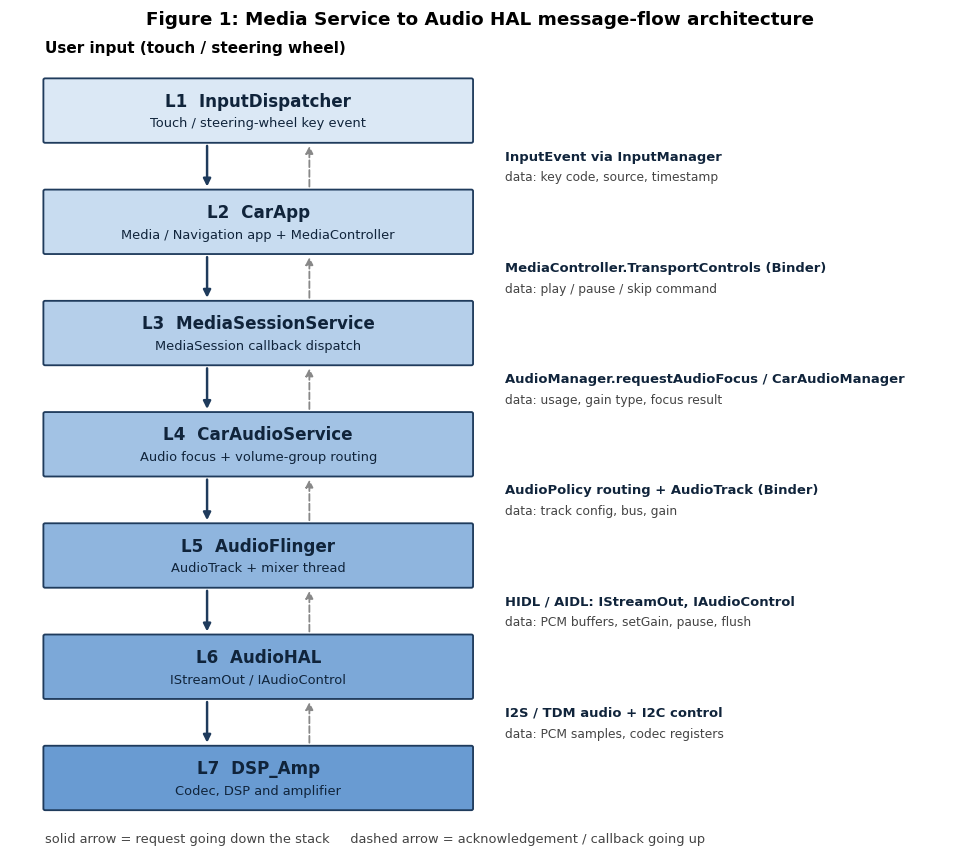

In [7]:
IFACES = [("InputEvent via InputManager", "key code, source, timestamp"),
          ("MediaController.TransportControls (Binder)", "play / pause / skip command"),
          ("AudioManager.requestAudioFocus / CarAudioManager", "usage, gain type, focus result"),
          ("AudioPolicy routing + AudioTrack (Binder)", "track config, bus, gain"),
          ("HIDL / AIDL: IStreamOut, IAudioControl", "PCM buffers, setGain, pause, flush"),
          ("I2S / TDM audio + I2C control", "PCM samples, codec registers")]
fig, ax = plt.subplots(figsize=(11, 9.6)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 10.6)
ys = [9.6 - i * 1.45 for i in range(len(LAYERS))]
palette = ["#dbe8f5", "#c8dcf0", "#b5cfea", "#a2c2e4", "#8fb5de", "#7ca8d8", "#699bd2"]
for i, (lid, tag, desc, mean, pid) in enumerate(LAYERS):
    ax.add_patch(FancyBboxPatch((0.4, ys[i] - 0.4), 5.0, 0.8, boxstyle="round,pad=0.02", fc=palette[i], ec="#1f3b5c", lw=1.2))
    ax.text(2.9, ys[i] + 0.12, f"{lid}  {tag}", ha="center", va="center", fontsize=11, weight="bold", color="#10243b")
    ax.text(2.9, ys[i] - 0.17, desc, ha="center", va="center", fontsize=8.5, color="#10243b")
    if i < len(LAYERS) - 1:
        ax.annotate("", xy=(2.3, ys[i + 1] + 0.42), xytext=(2.3, ys[i] - 0.42), arrowprops=dict(arrowstyle="-|>", color="#1f3b5c", lw=1.6))
        ax.annotate("", xy=(3.5, ys[i] - 0.42), xytext=(3.5, ys[i + 1] + 0.42), arrowprops=dict(arrowstyle="-|>", color="#888", lw=1.2, ls="--"))
        ax.text(5.8, (ys[i] + ys[i + 1]) / 2 + 0.12, IFACES[i][0], fontsize=8.6, va="center", weight="bold", color="#10243b")
        ax.text(5.8, (ys[i] + ys[i + 1]) / 2 - 0.15, "data: " + IFACES[i][1], fontsize=8, va="center", color="#444")
ax.text(0.4, 10.35, "User input (touch / steering wheel)", fontsize=10, weight="bold")
ax.text(0.4, 0.05, "solid arrow = request going down the stack     dashed arrow = acknowledgement / callback going up", fontsize=8.5, color="#444")
ax.set_title("Figure 1: Media Service to Audio HAL message-flow architecture", fontsize=12, weight="bold", pad=6)
fig.savefig(OUT / "figures/fig1_architecture.png", bbox_inches="tight", dpi=170); plt.show()

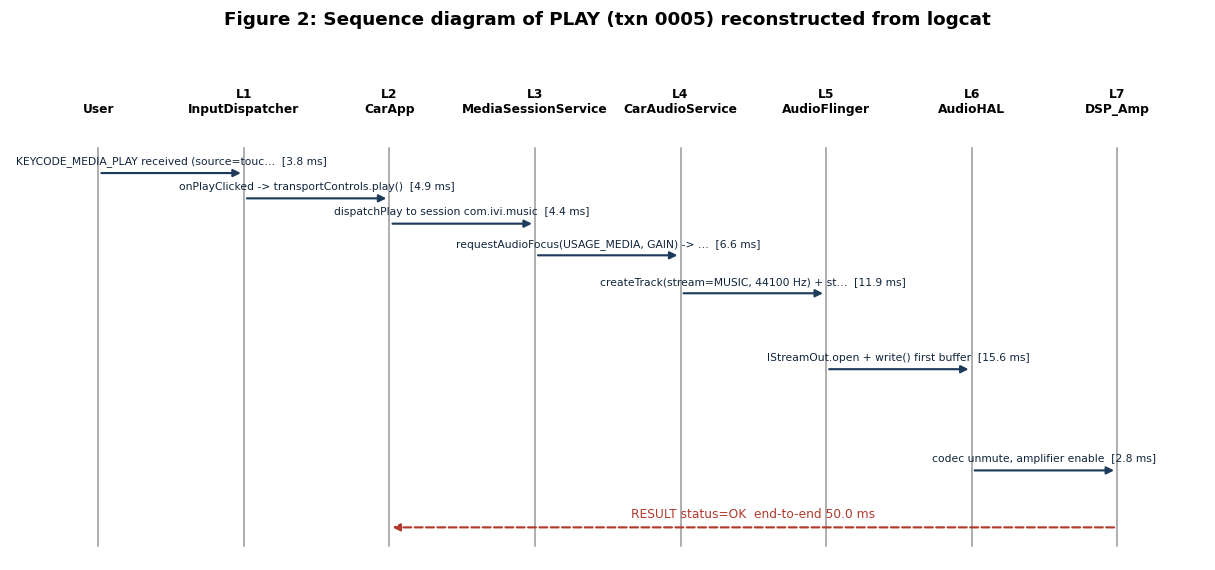

In [8]:
tid_play = txns[(txns.action == "PLAY") & (txns.status == "OK")].txn.iloc[0]
seq = ev[ev.txn == tid_play].sort_values("ts").reset_index(drop=True)
t0 = seq.ts.iloc[0]; seq["y"] = (seq.ts - t0).dt.total_seconds() * 1000
names = ["User"] + [f"{l[0]} {l[1]}" for l in LAYERS]
xs = {n: i for i, n in enumerate(names)}
fig, ax = plt.subplots(figsize=(14, 6.2))
ymax = seq.y.max() + 12
for n, x in xs.items():
    ax.plot([x, x], [-4, ymax], color="#999", lw=1, zorder=0)
    ax.text(x, -9, n.replace(" ", "\n"), ha="center", va="bottom", fontsize=8, weight="bold")
prev_x = 0
for _, r in seq.iterrows():
    x = LAYER_IDS.index(r.layer_id) + 1
    ax.annotate("", xy=(x, r.y), xytext=(prev_x, r.y), arrowprops=dict(arrowstyle="-|>", color="#1f3b5c", lw=1.4))
    label = r.message if len(r.message) < 42 else r.message[:40] + "…"
    ax.text((x + prev_x) / 2, r.y - 1.4, f"{label}  [{r.dt_ms:.1f} ms]", ha="center", fontsize=7, color="#10243b")
    prev_x = x
res_row = txns[txns.txn == tid_play].iloc[0]
ax.annotate("", xy=(2, ymax - 3), xytext=(7, ymax - 3), arrowprops=dict(arrowstyle="-|>", color="#b03a2e", lw=1.4, ls="--"))
ax.text(4.5, ymax - 4.6, f"RESULT status={res_row.status}  end-to-end {res_row.e2e_ms:.1f} ms", ha="center", fontsize=8, color="#b03a2e")
ax.set_ylim(ymax + 2, -22); ax.set_xlim(-.6, 7.6); ax.axis("off")
ax.set_title(f"Figure 2: Sequence diagram of PLAY (txn {tid_play:04d}) reconstructed from logcat", fontsize=12, weight="bold")
fig.savefig(OUT / "figures/fig2_sequence.png", bbox_inches="tight", dpi=170); plt.show()

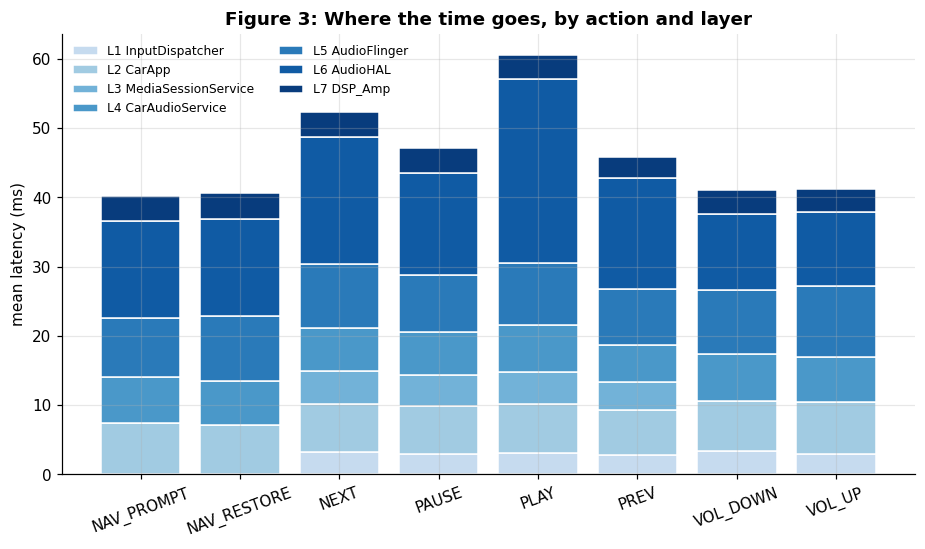

In [9]:
fig, ax = plt.subplots(figsize=(10, 5.2)); bottom = np.zeros(len(by_action_layer))
cols = plt.cm.Blues(np.linspace(.25, .95, len(LAYERS)))
for c, lid in zip(cols, LAYER_IDS):
    ax.bar(by_action_layer.index, by_action_layer[lid], bottom=bottom, label=f"{lid} {TAG[lid]}", color=c, edgecolor="white")
    bottom += by_action_layer[lid].values
ax.set_ylabel("mean latency (ms)"); ax.set_title("Figure 3: Where the time goes, by action and layer", weight="bold")
ax.legend(fontsize=8, ncol=2, frameon=False); plt.xticks(rotation=20)
fig.savefig(OUT / "figures/fig3_layer_latency.png", bbox_inches="tight", dpi=170); plt.show()

/tmp/ipykernel_88/3545965530.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([ok[ok.action == a].e2e_ms for a in order], labels=order, showfliers=True, patch_artist=True,


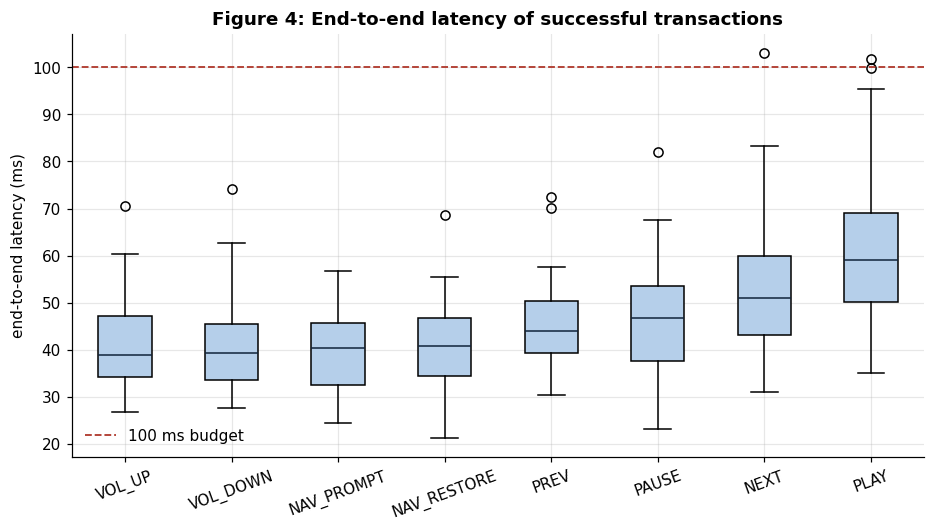

In [10]:
order = list(e2e.sort_values("median").index)
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([ok[ok.action == a].e2e_ms for a in order], labels=order, showfliers=True, patch_artist=True,
           boxprops=dict(facecolor="#b5cfea"), medianprops=dict(color="#10243b"))
ax.axhline(BUDGET, color="#b03a2e", ls="--", lw=1.2, label=f"{BUDGET:.0f} ms budget")
ax.set_ylabel("end-to-end latency (ms)"); ax.legend(frameon=False)
ax.set_title("Figure 4: End-to-end latency of successful transactions", weight="bold"); plt.xticks(rotation=20)
fig.savefig(OUT / "figures/fig4_e2e_boxplot.png", bbox_inches="tight", dpi=170); plt.show()

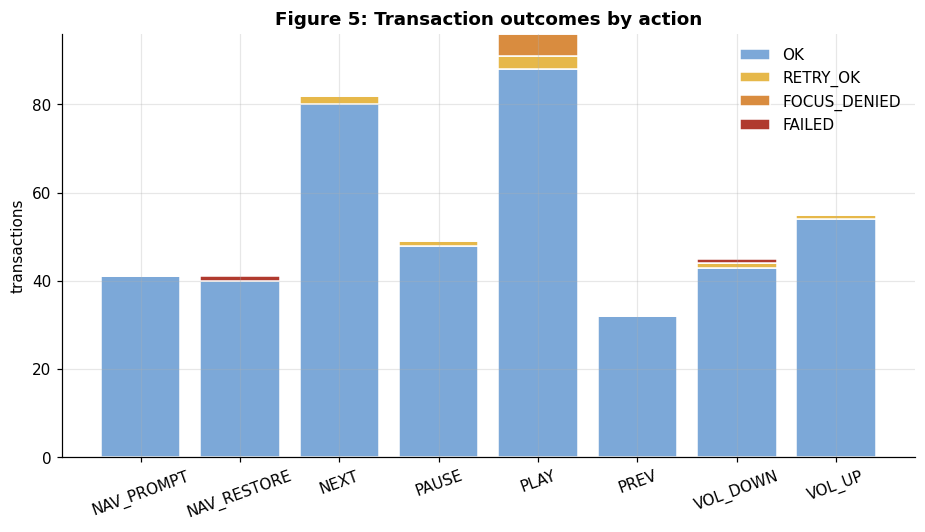

In [11]:
oc = txns.pivot_table(index="action", columns="status", values="txn", aggfunc="count").fillna(0)
oc = oc.reindex(columns=[c for c in ["OK", "RETRY_OK", "FOCUS_DENIED", "FAILED"] if c in oc.columns])
colors = {"OK": "#7ca8d8", "RETRY_OK": "#e6b84a", "FOCUS_DENIED": "#d98c3f", "FAILED": "#b03a2e"}
fig, ax = plt.subplots(figsize=(10, 5)); bottom = np.zeros(len(oc))
for s in oc.columns:
    ax.bar(oc.index, oc[s], bottom=bottom, label=s, color=colors[s], edgecolor="white"); bottom += oc[s].values
ax.set_ylabel("transactions"); ax.legend(frameon=False); plt.xticks(rotation=20)
ax.set_title("Figure 5: Transaction outcomes by action", weight="bold")
fig.savefig(OUT / "figures/fig5_outcomes.png", bbox_inches="tight", dpi=170); plt.show()

In [12]:
nav = int(txns[txns.action == "NAV_PROMPT"].txn.min())
restore = int(txns[(txns.action == "NAV_RESTORE") & (txns.txn > nav)].txn.min())
for t in (nav, restore):
    print("\n".join(l for l in log_lines if f"[txn={t:04d}]" in l)); print()

09-29 09:00:37.081  1544  1547 I CarApp              : [txn=0003] [NAV_PROMPT] NavigationApp voice prompt: 'turn left in 200 m' | dt=11.93ms
09-29 09:00:37.093  1021  1021 I CarAudioService     : [txn=0003] [NAV_PROMPT] requestAudioFocus(NAV_GUIDANCE, GAIN_TRANSIENT_MAY_DUCK) -> media ducked | dt=5.18ms
09-29 09:00:37.098   690   693 I AudioFlinger        : [txn=0003] [NAV_PROMPT] duck media track gain 1.0 -> 0.5 | dt=8.16ms
09-29 09:00:37.106   702   705 I AudioHAL            : [txn=0003] [NAV_PROMPT] IAudioControl.onAudioFocusChange(DUCK) | dt=23.17ms
09-29 09:00:37.129   655   658 I DSP_Amp             : [txn=0003] [NAV_PROMPT] DSP gain -6 dB on media bus | dt=3.28ms
09-29 09:00:37.132  1544  1546 I CarApp              : [txn=0003] [NAV_PROMPT] RESULT status=OK e2e=51.71ms | dt=0.00ms

09-29 09:00:42.364  1544  1545 I CarApp              : [txn=0004] [NAV_RESTORE] NavigationApp prompt finished | dt=8.28ms
09-29 09:00:42.372  1021  1023 I CarAudioService     : [txn=0004] [NAV_RESTORE

In [13]:
slowest = layer_stats["mean"].idxmax()
metrics = dict(
    n_log_lines=len(log_lines), n_transactions=int(len(txns)), n_user_actions=int((txns.action != "NAV_RESTORE").sum()),
    outcomes={k: int(v) for k, v in outcome_counts.items()}, success_rate_pct=round(success_rate, 1),
    within_budget_pct=round(within_budget, 1), budget_ms=BUDGET,
    e2e=e2e.reset_index().to_dict(orient="records"),
    layer_stats=layer_stats.reset_index().to_dict(orient="records"),
    warn_error_by_layer={k: int(v) for k, v in fail_by_layer.items()},
    example_txn=int(tid_play), nav_txn=nav, restore_txn=restore,
    slowest_layer=slowest)
(OUT / "metrics.json").write_text(json.dumps(metrics, indent=2, default=float))
print(json.dumps({k: metrics[k] for k in ["n_log_lines", "n_transactions", "outcomes", "success_rate_pct", "within_budget_pct", "slowest_layer"]}, indent=2))

try:
    from google.colab import files
    import shutil; shutil.make_archive("ivi_outputs", "zip", OUT); files.download("ivi_outputs.zip")
except ImportError:
    print("Not running in Colab; files are in", OUT.resolve())

{
  "n_log_lines": 3257,
  "n_transactions": 441,
  "outcomes": {
    "OK": 426,
    "RETRY_OK": 8,
    "FOCUS_DENIED": 5,
    "FAILED": 2
  },
  "success_rate_pct": 98.4,
  "within_budget_pct": 99.5,
  "slowest_layer": "L6"
}
Not running in Colab; files are in /home/claude/m6/ivi_outputs
